In [5]:
import numpy as np
import matplotlib.pyplot as plt
import batman
import emcee
import corner

# load K2 data
data = np.loadtxt(
    "../data/apjladf06ft3_mrt.txt",
    skiprows=15
)

t = data[:, 0] + 2454833 #offset to BJD
flux = data[:, 2]

# published mid-transit time from Venner et al. (2026)
t0_published = 2458055.0969

mask = np.abs(t - t0_published) < 0.8 # keep only data points within +/- 0.8 days (19.2h) around the transit

t_transit = t[mask]
flux_transit = flux[mask]

In [6]:
# Gravitational constant in SI units
G = 6.67430e-11

# the paper finds an out-of-transit scatter of about 32 ppm
# for the K2 light curve.
sigma_flux = 32e-6

# Stellar-density prior from Venner et al. (2026):
# log10(rho_star / (g cm^-3)) = 0.462 +/- 0.041
logrho_mean = 0.462
logrho_sigma = 0.041

# Limb-darkening priors in the Kepler band
u1_mean = 0.60
u1_sigma = 0.07

u2_mean = 0.12
u2_sigma = 0.07

In [7]:
def a_over_rstar(period, rho_star):
    """
    Calculate a/R_star using Kepler's third law.

    period   : orbital period in days
    rho_star : stellar density in g/cm^3
    """

    # days -> seconds
    period_seconds = period * 24 * 60 * 60

    # g/cm^3 -> kg/m^3
    rho_si = rho_star * 1000

    return (
        G * rho_si * period_seconds**2
        / (3 * np.pi)
    )**(1/3)

print(a_over_rstar(355, 2.90))

268.33187277032084


In [8]:
# Starting parameter object only used to initialise batman
batman_params = batman.TransitParams()

batman_params.t0 = t0_published
batman_params.per = 355.0
batman_params.rp = 0.01368
batman_params.a = 270.0
batman_params.inc = 90.0

batman_params.ecc = 0.0
batman_params.w = 90.0

batman_params.u = [0.60, 0.12]
batman_params.limb_dark = "quadratic"

# The K2 exposure time was 29.4 minutes.
# The paper supersamples each exposure by a factor of 10.
batman_model = batman.TransitModel(
    batman_params,
    t_transit,
    supersample_factor=10,
    exp_time=29.4 / (24 * 60)
)

In [9]:
def transit_model(theta):
    """
    Circular transit model.

    theta =
    (period, b, rp, t0, rho_star, u1, u2)
    """

    period, b, rp, t0, rho_star, u1, u2 = theta

    # Calculate a/Rstar from period and stellar density
    a_Rstar = a_over_rstar(period, rho_star)

    # For a circular orbit:
    # b = (a/Rstar) * cos(i)
    cos_i = b / a_Rstar

    # Reject geometrically impossible solutions
    if cos_i < 0 or cos_i > 1:
        return None

    inclination = np.degrees(np.arccos(cos_i))

    # Update the batman parameters
    batman_params.t0 = t0
    batman_params.per = period
    batman_params.rp = rp
    batman_params.a = a_Rstar
    batman_params.inc = inclination

    # Circular orbit for our baseline model
    batman_params.ecc = 0.0
    batman_params.w = 90.0

    batman_params.u = [u1, u2]

    return batman_model.light_curve(batman_params)

In [10]:
def log_prior(theta):
    """
    Priors for the circular baseline model.

    We try to follow the assumptions of Venner et al. (2026)
    more closely here.
    """

    period, b, rp, t0, rho_star, u1, u2 = theta


    # ----- Basic physical limits -----

    # No second transit was seen during K2, so the period
    # must be longer than about 64 days.
    # Venner et al. use 2000 d as an upper limit.
    if not 64 < period < 2000:
        return -np.inf

    if not 0 <= b < 1:
        return -np.inf

    if not 0.005 < rp < 0.03:
        return -np.inf

    if not t0_published - 0.1 < t0 < t0_published + 0.1:
        return -np.inf

    if rho_star <= 0:
        return -np.inf


    # Physical conditions for quadratic limb darkening
    if not (
        u1 > 0
        and u1 + u2 < 1
        and u1 + 2*u2 > 0
    ):
        return -np.inf


    lp = 0.0


    # ----- Single-transit period prior -----
    #
    # Long-period planets are less likely to have happened
    # to transit during the observing window.
    #
    # Venner et al. use the Kipping (2018) single-transit prior,
    # which scales approximately as P^(-5/3).

    lp += -(5/3) * np.log(period)


    # ----- Stellar density prior -----
    #
    # Venner et al. use:
    # log10(rho_star) = 0.462 +/- 0.041

    log_rho = np.log10(rho_star)

    lp += -0.5 * (
        (log_rho - 0.462) / 0.041
    )**2


    # ----- Limb-darkening priors -----

    lp += -0.5 * ((u1 - 0.60) / 0.07)**2
    lp += -0.5 * ((u2 - 0.12) / 0.07)**2


    # Radius ratio was fitted approximately log-uniformly,
    # so add the corresponding 1/rp prior.
    lp += -np.log(rp)


    return lp

In [11]:
#prior

def log_prior(theta):
    """
    Priors for the circular baseline model.

    We try to follow Venner et al. (2026) as closely as
    possible from the description in the paper.
    """

    period, b, rp, t0, rho_star, u1, u2 = theta


    # --------------------------------------------------
    # Basic allowed parameter ranges
    # --------------------------------------------------

    # No second K2 transit was seen, giving P > ~64 d.
    # The paper sets an upper limit of 2000 d.
    if not 64 < period < 2000:
        return -np.inf

    # A transit is possible up to approximately b = 1 + Rp/Rstar.
    if not 0 <= b < 1 + rp:
        return -np.inf

    if not 0.005 < rp < 0.03:
        return -np.inf

    # We already know quite accurately where the transit occurred.
    if not t0_published - 0.1 < t0 < t0_published + 0.1:
        return -np.inf

    if rho_star <= 0:
        return -np.inf


    # --------------------------------------------------
    # Physical quadratic limb-darkening conditions
    # --------------------------------------------------

    if not (
        u1 > 0
        and u1 + u2 < 1
        and u1 + 2*u2 > 0
    ):
        return -np.inf


    # Check that the geometry itself is possible
    a_Rstar = a_over_rstar(period, rho_star)

    if b > a_Rstar:
        return -np.inf


    lp = 0.0


    # --------------------------------------------------
    # Period prior
    # --------------------------------------------------

    # The paper fits P log-uniformly...
    lp += -np.log(period)

    # ...and additionally applies the Kipping single-transit
    # probability prior. The paper states that its long-period
    # behaviour scales approximately as P^(-5/3).
    #
    # This is our approximation of that prior from the
    # description in the paper.
    lp += -(5/3) * np.log(period)


    # --------------------------------------------------
    # Radius-ratio prior
    # --------------------------------------------------

    # Rp/Rstar is fitted log-uniformly in the paper
    lp += -np.log(rp)


    # --------------------------------------------------
    # Stellar-density prior
    # --------------------------------------------------

    # rho_star is fitted log-uniformly
    lp += -np.log(rho_star)

    # plus the stellar constraint:
    # log10(rho_star) = 0.462 +/- 0.041
    log_rho = np.log10(rho_star)

    lp += -0.5 * (
        (log_rho - logrho_mean) / logrho_sigma
    )**2


    # --------------------------------------------------
    # Limb-darkening priors
    # --------------------------------------------------

    lp += -0.5 * ((u1 - u1_mean) / u1_sigma)**2
    lp += -0.5 * ((u2 - u2_mean) / u2_sigma)**2


    return lp

In [12]:
#likelihood

def log_likelihood(theta):
    """
    Gaussian likelihood comparing the observed flux
    with the transit model.
    """

    model_flux = transit_model(theta)

    # Invalid transit geometry
    if model_flux is None:
        return -np.inf

    if not np.all(np.isfinite(model_flux)):
        return -np.inf

    residuals = flux_transit - model_flux

    return -0.5 * np.sum(
        residuals**2 / sigma_flux**2
        + np.log(2 * np.pi * sigma_flux**2)
    )

In [13]:
#posterior

def log_probability(theta):
    """
    log posterior = log prior + log likelihood
    """

    lp = log_prior(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood(theta)

In [14]:
#quick test
theta_test = (
    355.0,          # period [days]
    0.3,            # impact parameter
    0.01368,        # Rp/Rstar
    t0_published,   # mid-transit time
    2.90,           # stellar density [g/cm^3]
    0.60,           # u1
    0.12            # u2
)

print("log prior:      ", log_prior(theta_test))
print("log likelihood: ", log_likelihood(theta_test))
print("log posterior:  ", log_probability(theta_test))

log prior:       -12.431918257644067
log likelihood:  601.7543505987007
log posterior:   589.3224323410567


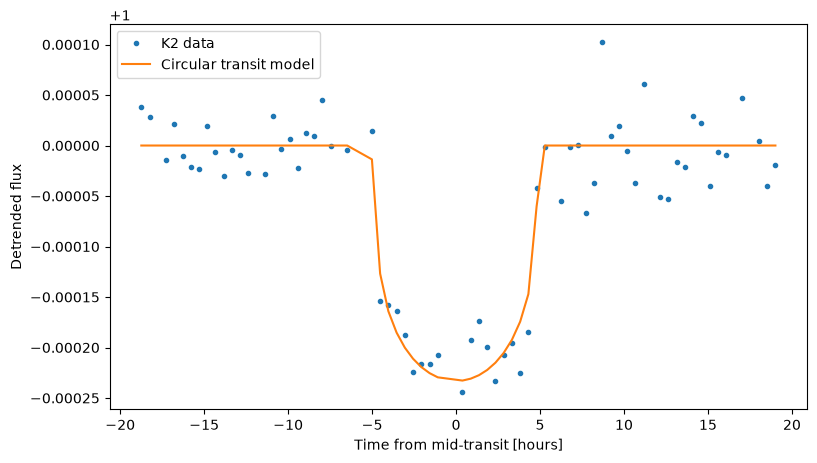

In [15]:
model_test = transit_model(theta_test)

plt.figure(figsize=(9, 5))

plt.plot(
    (t_transit - t0_published) * 24,
    flux_transit,
    ".",
    label="K2 data"
)

plt.plot(
    (t_transit - t0_published) * 24,
    model_test,
    label="Circular transit model"
)

plt.xlabel("Time from mid-transit [hours]")
plt.ylabel("Detrended flux")
plt.legend()
plt.show()

In [16]:
#mcmc
ndim = 7
nwalkers = 50

labels = [
    "Period [d]",
    "b",
    "Rp/Rstar",
    "t0 [BJD]",
    "rho_star",
    "u1",
    "u2"
]

initial = np.array([
    355.0,
    0.3,
    0.01368,
    t0_published,
    2.90,
    0.60,
    0.12
])

spread = np.array([
    30.0,      # period
    0.15,      # b
    0.0005,    # Rp/Rstar
    0.005,     # t0
    0.10,      # rho_star
    0.03,      # u1
    0.03       # u2
])

rng = np.random.default_rng(42)

In [17]:
acceptance = sampler.acceptance_fraction

print("Mean acceptance fraction:")
print(np.mean(acceptance))

NameError: name 'sampler' is not defined

In [18]:
samples = sampler.get_chain()

labels = [
    "Period [d]",
    "b",
    "Rp/Rstar",
    "t0 [BJD]",
    "rho_star",
    "u1",
    "u2"
]

fig, axes = plt.subplots(
    len(labels),
    figsize=(10, 12),
    sharex=True
)

for i in range(len(labels)):
    axes[i].plot(samples[:, :, i], alpha=0.25)
    axes[i].set_ylabel(labels[i])

axes[-1].set_xlabel("MCMC step")

plt.tight_layout()
plt.show()

NameError: name 'sampler' is not defined

In [19]:
pos = []

while len(pos) < nwalkers:

    candidate = initial + spread * rng.normal(size=ndim)

    if np.isfinite(log_probability(candidate)):
        pos.append(candidate)

pos = np.array(pos)

print(pos.shape)

(50, 7)


In [20]:
#first check

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_probability
)

sampler.run_mcmc(
    pos,
    10000,
    progress=True
)

You must install the tqdm library to use progress indicators with emcee


State([[ 4.29645130e+02  3.17645837e-01  1.40792343e-02  2.45805510e+06
   3.33480062e+00  5.91781369e-01  8.65830933e-02]
 [ 3.68393784e+02  3.92453134e-04  1.30085826e-02  2.45805509e+06
   3.24298699e+00  5.32317716e-01  1.53991500e-01]
 [ 3.17086624e+02  9.79738025e-02  1.37137277e-02  2.45805510e+06
   3.00407956e+00  4.07303228e-01  1.91140625e-01]
 [ 2.56013765e+02  8.90998893e-02  1.35314228e-02  2.45805510e+06
   2.48795542e+00  4.75295566e-01  1.82740760e-01]
 [ 2.63972705e+02  2.94385905e-01  1.40273376e-02  2.45805509e+06
   2.45341561e+00  5.32086956e-01 -1.63027873e-02]
 [ 3.25082444e+02  6.46692395e-02  1.33787963e-02  2.45805510e+06
   3.04351098e+00  5.53375363e-01  7.70967150e-03]
 [ 3.56042953e+02  2.88737572e-01  1.34383231e-02  2.45805509e+06
   2.90806289e+00  6.11729600e-01  9.12730942e-02]
 [ 5.13922447e+02  5.07786655e-01  1.38137146e-02  2.45805510e+06
   3.11488218e+00  5.18989387e-01  1.28945922e-01]
 [ 3.01523904e+02  1.61110463e-01  1.39527681e-02  2.45805

In [21]:
print(sampler.get_chain().shape)

(10000, 50, 7)


In [22]:
#diagonstics
print(
    "Mean acceptance fraction:",
    np.mean(sampler.acceptance_fraction)
)

tau = sampler.get_autocorr_time(tol=0)

for label, value in zip(labels, tau):
    print(f"{label}: tau = {value:.1f}")

print()
print("Chain length / tau:")

for label, value in zip(labels, tau):
    print(
        f"{label}: "
        f"{sampler.iteration / value:.1f}"
    )

Mean acceptance fraction: 0.366892
Period [d]: tau = 363.6
b: tau = 300.6
Rp/Rstar: tau = 272.0
t0 [BJD]: tau = 126.8
rho_star: tau = 112.6
u1: tau = 129.8
u2: tau = 122.2

Chain length / tau:
Period [d]: 27.5
b: 33.3
Rp/Rstar: 36.8
t0 [BJD]: 78.9
rho_star: 88.8
u1: 77.0
u2: 81.8


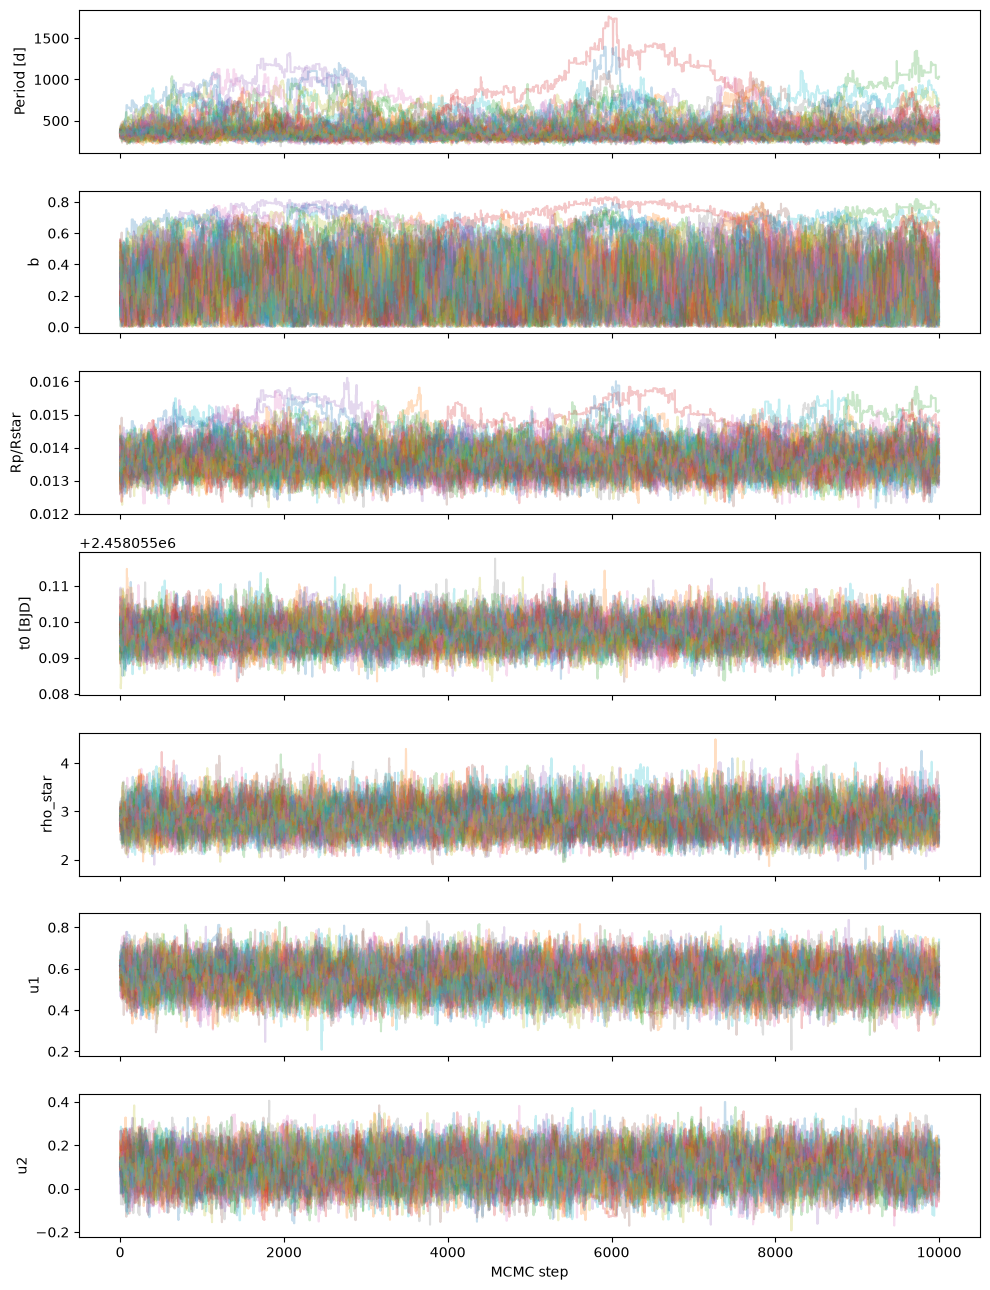

In [23]:
chain = sampler.get_chain()

fig, axes = plt.subplots(
    ndim,
    figsize=(10, 13),
    sharex=True
)

for i in range(ndim):

    axes[i].plot(
        chain[:, :, i],
        alpha=0.25
    )

    axes[i].set_ylabel(labels[i])

axes[-1].set_xlabel("MCMC step")

plt.tight_layout()
plt.show()

In [24]:
#stability check

chain = sampler.get_chain()

N = sampler.iteration

# Compare two later sections of the chain.
# We deliberately ignore the first quarter.
start = N // 4
middle = (start + N) // 2

samples_earlier = chain[start:middle].reshape(-1, ndim)
samples_later = chain[middle:N].reshape(-1, ndim)

for i, label in enumerate(labels):

    q_earlier = np.percentile(
        samples_earlier[:, i],
        [16, 50, 84]
    )

    q_later = np.percentile(
        samples_later[:, i],
        [16, 50, 84]
    )

    print(label)
    print("  earlier:", q_earlier)
    print("  later:  ", q_later)

Period [d]
  earlier: [293.5627572  348.32812612 488.31182121]
  later:   [292.32441433 347.08905739 483.6204359 ]
b
  earlier: [0.08906596 0.27916491 0.52438413]
  later:   [0.08397888 0.2708632  0.51923822]
Rp/Rstar
  earlier: [0.01326989 0.01364514 0.01411471]
  later:   [0.01326828 0.01364702 0.01413584]
t0 [BJD]
  earlier: [2458055.09381293 2458055.0969489  2458055.10017573]
  later:   [2458055.09384518 2458055.09701239 2458055.100217  ]
rho_star
  earlier: [2.59960825 2.84704351 3.12055757]
  later:   [2.59129648 2.85925121 3.14814581]
u1
  earlier: [0.49328414 0.55865204 0.62371354]
  later:   [0.48535868 0.55131376 0.61944899]
u2
  earlier: [0.02663378 0.09731258 0.16658374]
  later:   [0.0312935  0.09974195 0.16682485]


In [25]:
#posterior samples

burnin = sampler.iteration // 2
thin = 100

flat_samples = sampler.get_chain(
    discard=burnin,
    thin=thin,
    flat=True
)

print("Total chain length:", sampler.iteration)
print("Burn-in:", burnin)
print("Posterior samples:", len(flat_samples))

Total chain length: 10000
Burn-in: 5000
Posterior samples: 2500


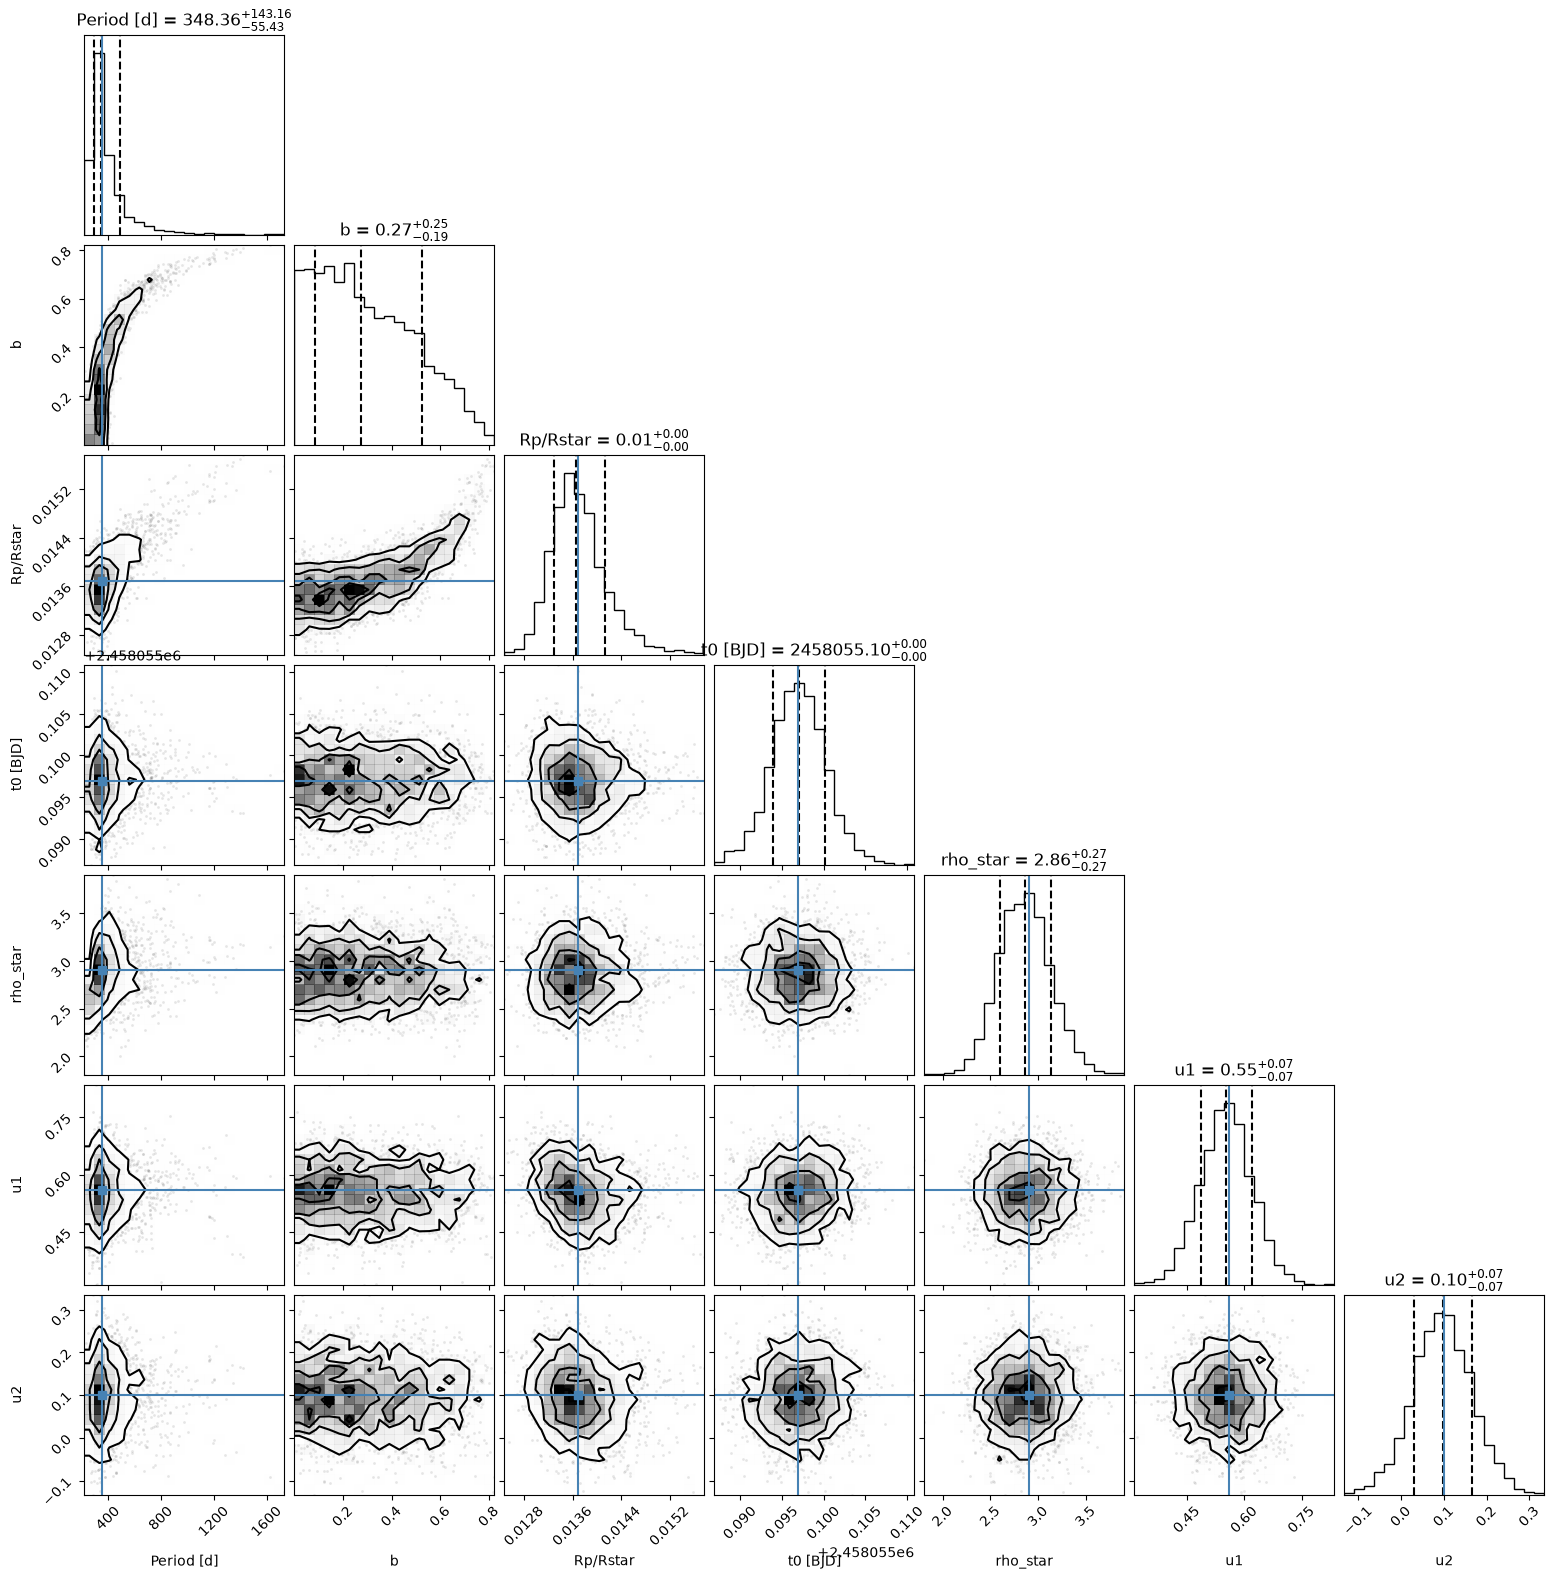

In [26]:
#corner plot

published_values = [
    355.0,
    None,           # paper does not give a median b
    0.01368,
    2458055.0969,
    2.90,
    0.56,
    0.10
]

fig = corner.corner(
    flat_samples,
    labels=labels,
    show_titles=True,
    quantiles=[0.16, 0.50, 0.84],
    truths=published_values
)

plt.show()

In [27]:
#numerical posterior summary

for i, label in enumerate(labels):

    q16, q50, q84 = np.percentile(
        flat_samples[:, i],
        [16, 50, 84]
    )

    print(
        f"{label}: "
        f"{q50:.5f} "
        f"-{q50-q16:.5f} "
        f"+{q84-q50:.5f}"
    )

Period [d]: 348.35560 -55.42648 +143.16280
b: 0.27292 -0.18783 +0.25060
Rp/Rstar: 0.01366 -0.00037 +0.00048
t0 [BJD]: 2458055.09705 -0.00316 +0.00309
rho_star: 2.86312 -0.26609 +0.27418
u1: 0.55317 -0.06714 +0.06586
u2: 0.09785 -0.06678 +0.06765


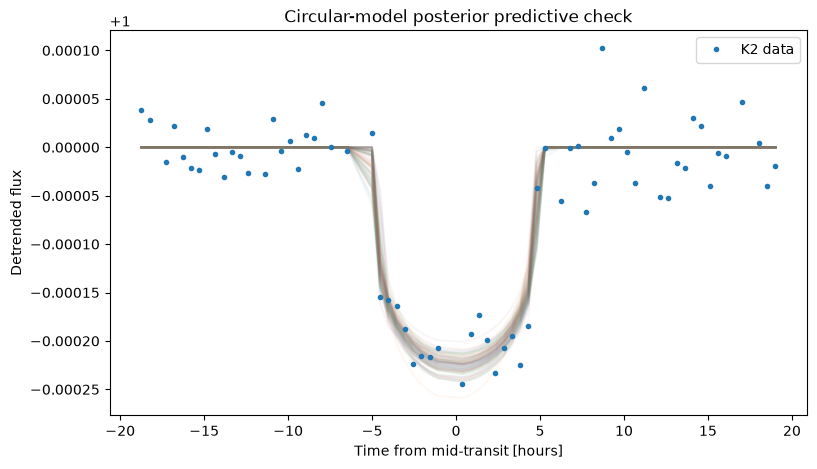

In [28]:
#posterior predictive check

rng = np.random.default_rng(1)

n_models = min(100, len(flat_samples))

indices = rng.choice(
    len(flat_samples),
    size=n_models,
    replace=False
)

plt.figure(figsize=(9, 5))

# Plot posterior transit models first
for index in indices:

    model_flux = transit_model(
        flat_samples[index]
    )

    plt.plot(
        (t_transit - t0_published) * 24,
        model_flux,
        alpha=0.05
    )

# Observations on top
plt.plot(
    (t_transit - t0_published) * 24,
    flux_transit,
    ".",
    label="K2 data"
)

plt.xlabel("Time from mid-transit [hours]")
plt.ylabel("Detrended flux")
plt.title("Circular-model posterior predictive check")
plt.legend()

plt.show()

In [29]:
#running another 10k steps

sampler.run_mcmc(
    None,
    10000,
    progress=True
)

You must install the tqdm library to use progress indicators with emcee


State([[ 6.41768155e+02  6.48068748e-01  1.47078896e-02  2.45805510e+06
   2.61151698e+00  6.19048205e-01  1.31973125e-01]
 [ 3.97489383e+02  2.61877190e-01  1.31033719e-02  2.45805510e+06
   3.05991802e+00  5.09659176e-01  2.20122445e-01]
 [ 8.52628473e+02  7.42021145e-01  1.50103318e-02  2.45805510e+06
   2.64811679e+00  5.50925244e-01  1.47806515e-02]
 [ 3.41181354e+02  2.13861127e-01  1.35296241e-02  2.45805510e+06
   2.86369266e+00  5.89838614e-01  4.59125022e-02]
 [ 2.94045448e+02  1.88108843e-03  1.38195145e-02  2.45805510e+06
   2.87459834e+00  5.64363153e-01  8.00359598e-02]
 [ 3.73002321e+02  2.99027496e-01  1.37588429e-02  2.45805510e+06
   3.10535661e+00  4.84230306e-01  7.33766502e-02]
 [ 3.02602841e+02  7.41696499e-02  1.34517844e-02  2.45805510e+06
   2.96327863e+00  5.04585809e-01  1.43699713e-01]
 [ 3.18909162e+02  4.43378092e-02  1.32850238e-02  2.45805510e+06
   2.93281027e+00  6.49233396e-01  1.01404718e-01]
 [ 4.12977677e+02  4.37745197e-01  1.37751022e-02  2.45805

In [30]:
tau = sampler.get_autocorr_time(tol=0)

for label, value in zip(labels, tau):
    print(
        f"{label}: tau = {value:.1f}, "
        f"N/tau = {sampler.iteration/value:.1f}"
    )

Period [d]: tau = 654.0, N/tau = 30.6
b: tau = 553.3, N/tau = 36.1
Rp/Rstar: tau = 494.1, N/tau = 40.5
t0 [BJD]: tau = 143.8, N/tau = 139.1
rho_star: tau = 136.2, N/tau = 146.9
u1: tau = 147.1, N/tau = 136.0
u2: tau = 138.7, N/tau = 144.2


In [31]:
np.save(
    "../data/circular_posterior.npy",
    flat_samples
)

In [32]:
burnin = sampler.iteration // 2
thin = 100

flat_samples = sampler.get_chain(
    discard=burnin,
    thin=thin,
    flat=True
)

print(np.percentile(flat_samples[:, 0], [16, 50, 84]))

[292.43356936 346.37567899 497.81600807]


In [33]:
np.save(
    "../data/posterior_circular.npy",
    flat_samples
)

In [34]:
# Comparison with the published posterior
'''
The posterior samples from Venner et al. (2026) were kindly provided by
Alexander Venner. We compare our circular model with their original
posterior as a validation of our implementation.
'''

'\nThe posterior samples from Venner et al. (2026) were kindly provided by\nAlexander Venner. We compare our circular model with their original\nposterior as a validation of our implementation.\n'

In [35]:
import pandas as pd

venner = pd.read_csv(
    "../data/posteriors.csv"
)

venner.head()

,Unnamed: 0,M,rho,t0,P,b,r_R,u1,u2
0,0,0.709915,2.578528,8055.092356,297.733655,0.080599,0.012973,0.584169,0.139645
1,1,0.709529,3.250602,8055.100124,855.556579,0.672178,0.014380,0.603069,0.068932
2,2,0.716158,2.946143,8055.093615,493.589244,0.467524,0.013940,0.507067,0.162546
3,3,0.712984,3.047560,8055.096365,352.326777,0.199494,0.013162,0.559873,0.104540
4,4,0.698526,2.969352,8055.101953,820.524902,0.698646,0.014109,0.512523,0.052414


In [36]:
period_venner = venner["P"].to_numpy()

print(
    "Venner posterior:",
    np.percentile(
        period_venner,
        [16, 50, 84]
    )
)

Venner posterior: [295.73383083 354.74547615 542.47323806]


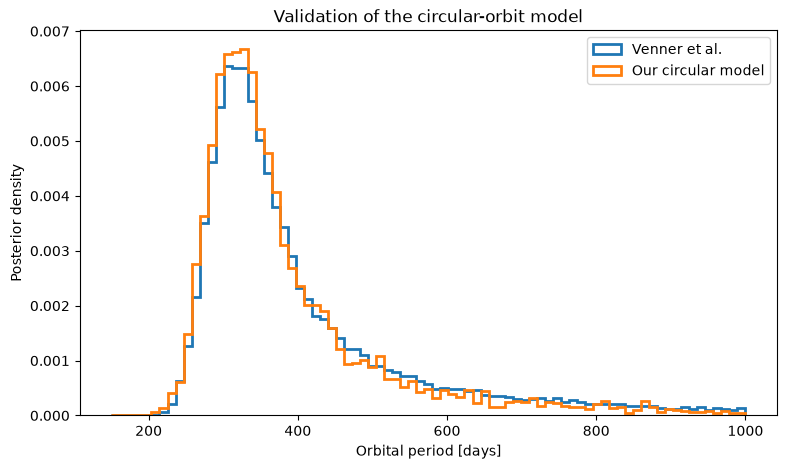

In [38]:
period_ours = flat_samples[:, 0]
bins = np.linspace(
    150,
    1000,
    80
)

plt.figure(figsize=(9, 5))

plt.hist(
    period_venner,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="Venner et al."
)

plt.hist(
    period_ours,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="Our circular model"
)

plt.xlabel("Orbital period [days]")
plt.ylabel("Posterior density")
plt.title("Validation of the circular-orbit model")

plt.legend()
plt.show()